In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df = pd.read_csv('heart.csv')

df_clean = df.copy()
df_clean['Cholesterol'] = df_clean['Cholesterol'].replace(0, df_clean.loc[df_clean['Cholesterol'] > 0, 'Cholesterol'].median())
df_clean['RestingBP'] = df_clean['RestingBP'].replace(0, df_clean.loc[df_clean['RestingBP'] > 0, 'RestingBP'].median())

df_encoded = pd.get_dummies(df_clean, drop_first=False, dtype=int)
X = df_encoded.drop('HeartDisease', axis=1)
y = df_encoded['HeartDisease']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Total Data Latih: ", len(X_train), " | Normal(0): ", (y_train == 0).sum(), " | Sakit Jantung (1): ", (y_train == 1).sum())
print("Total Data Uji: ", len(X_test), " | Normal(0): ", (y_test == 0).sum(), " | Sakit Jantung (1): ", (y_test == 1).sum())

Total Data Latih:  734  | Normal(0):  328  | Sakit Jantung (1):  406
Total Data Uji:  184  | Normal(0):  82  | Sakit Jantung (1):  102


Gini Impurity Awal (Sebelum Split): 0.4944



,Fitur,Threshold Split,Gini Cabang Kiri,Gini Cabang Kanan,Gini Setelah Split,Penurunan Gini (Gini Gain)
0,ST_Slope_Up,0.50,0.2804,0.2938,0.2861,0.2082
1,ST_Slope_Flat,0.50,0.3885,0.2801,0.3333,0.1611
2,ChestPainType_ASY,0.50,0.3932,0.3357,0.3616,0.1327
3,ExerciseAngina_N,0.50,0.2596,0.4551,0.3752,0.1191
4,ExerciseAngina_Y,0.50,0.4551,0.2596,0.3752,0.1191
5,Oldpeak,0.45,0.4493,0.3696,0.4085,0.0859
6,ChestPainType_ATA,0.50,0.4567,0.2404,0.4166,0.0777
7,MaxHR,132.50,0.3568,0.4716,0.4205,0.0739


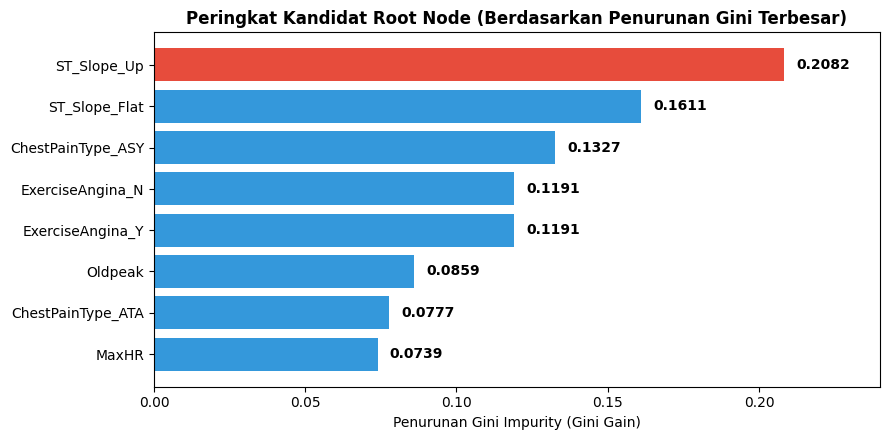

In [8]:
n_total = len(y_train)
gini_awal = 1.0 - (((y_train == 0).sum() / n_total)**2 + ((y_train == 1).sum() / n_total)**2)
print(f"Gini Impurity Awal (Sebelum Split): {gini_awal:.4f}\n")

kandidat_root = []
for col in X_train.columns:
    stump = DecisionTreeClassifier(criterion='gini', max_depth=1, random_state=42)
    stump.fit(X_train[[col]], y_train)
    t = stump.tree_
    weighted_gini = (t.n_node_samples[1] / n_total) * t.impurity[1] + (t.n_node_samples[2] / n_total) * t.impurity[2]
    kandidat_root.append({
        'Fitur': col,
        'Threshold Split': round(t.threshold[0], 2),
        'Gini Cabang Kiri': round(t.impurity[1], 4),
        'Gini Cabang Kanan': round(t.impurity[2], 4),
        'Gini Setelah Split': round(weighted_gini, 4),
        'Penurunan Gini (Gini Gain)': round(gini_awal - weighted_gini, 4)
    })

df_root = pd.DataFrame(kandidat_root).sort_values(by='Penurunan Gini (Gini Gain)', ascending=False).reset_index(drop=True)
display(df_root.head(8))

plt.figure(figsize=(9, 4.5))
top8 = df_root.head(8)
warna = ['#e74c3c' if i == 0 else '#3498db' for i in range(len(top8))]
bars = plt.barh(top8['Fitur'][::-1], top8['Penurunan Gini (Gini Gain)'][::-1], color=warna[::-1])
plt.title('Peringkat Kandidat Root Node (Berdasarkan Penurunan Gini Terbesar)', fontweight='bold')
plt.xlabel('Penurunan Gini Impurity (Gini Gain)')
plt.xlim(0, 0.24)
for bar in bars:
    plt.text(bar.get_width() + 0.004, bar.get_y() + bar.get_height()/2, f'{bar.get_width():.4f}', va='center', fontweight='bold')
plt.tight_layout()
plt.show()


Gini Impurity Awal (Sebelum Split): 0.4944



,Fitur,Threshold Split,Gini Cabang Kiri,Gini Cabang Kanan,Gini Setelah Split,Penurunan Gini (Gini Gain)
0,ST_Slope_Up,0.50,0.2804,0.2938,0.2861,0.2082
1,ST_Slope_Flat,0.50,0.3885,0.2801,0.3333,0.1611
2,ChestPainType_ASY,0.50,0.3932,0.3357,0.3616,0.1327
3,ExerciseAngina_N,0.50,0.2596,0.4551,0.3752,0.1191
4,ExerciseAngina_Y,0.50,0.4551,0.2596,0.3752,0.1191
5,Oldpeak,0.45,0.4493,0.3696,0.4085,0.0859
6,ChestPainType_ATA,0.50,0.4567,0.2404,0.4166,0.0777
7,MaxHR,132.50,0.3568,0.4716,0.4205,0.0739


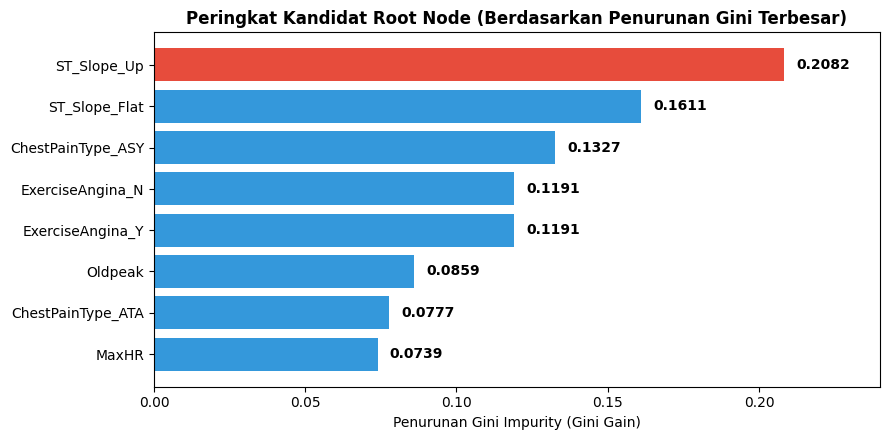

In [9]:
n_total = len(y_train)
gini_awal = 1.0 - (((y_train == 0).sum() / n_total)**2 + ((y_train == 1).sum() / n_total)**2)
print(f"Gini Impurity Awal (Sebelum Split): {gini_awal:.4f}\n")

kandidat_root = []
for col in X_train.columns:
    stump = DecisionTreeClassifier(criterion='gini', max_depth=1, random_state=42)
    stump.fit(X_train[[col]], y_train)
    t = stump.tree_
    weighted_gini = (t.n_node_samples[1] / n_total) * t.impurity[1] + (t.n_node_samples[2] / n_total) * t.impurity[2]
    kandidat_root.append({
        'Fitur': col,
        'Threshold Split': round(t.threshold[0], 2),
        'Gini Cabang Kiri': round(t.impurity[1], 4),
        'Gini Cabang Kanan': round(t.impurity[2], 4),
        'Gini Setelah Split': round(weighted_gini, 4),
        'Penurunan Gini (Gini Gain)': round(gini_awal - weighted_gini, 4)
    })

df_root = pd.DataFrame(kandidat_root).sort_values(by='Penurunan Gini (Gini Gain)', ascending=False).reset_index(drop=True)
display(df_root.head(8))

plt.figure(figsize=(9, 4.5))
top8 = df_root.head(8)
warna = ['#e74c3c' if i == 0 else '#3498db' for i in range(len(top8))]
bars = plt.barh(top8['Fitur'][::-1], top8['Penurunan Gini (Gini Gain)'][::-1], color=warna[::-1])
plt.title('Peringkat Kandidat Root Node (Berdasarkan Penurunan Gini Terbesar)', fontweight='bold')
plt.xlabel('Penurunan Gini Impurity (Gini Gain)')
plt.xlim(0, 0.24)
for bar in bars:
    plt.text(bar.get_width() + 0.004, bar.get_y() + bar.get_height()/2, f'{bar.get_width():.4f}', va='center', fontweight='bold')
plt.tight_layout()
plt.show()


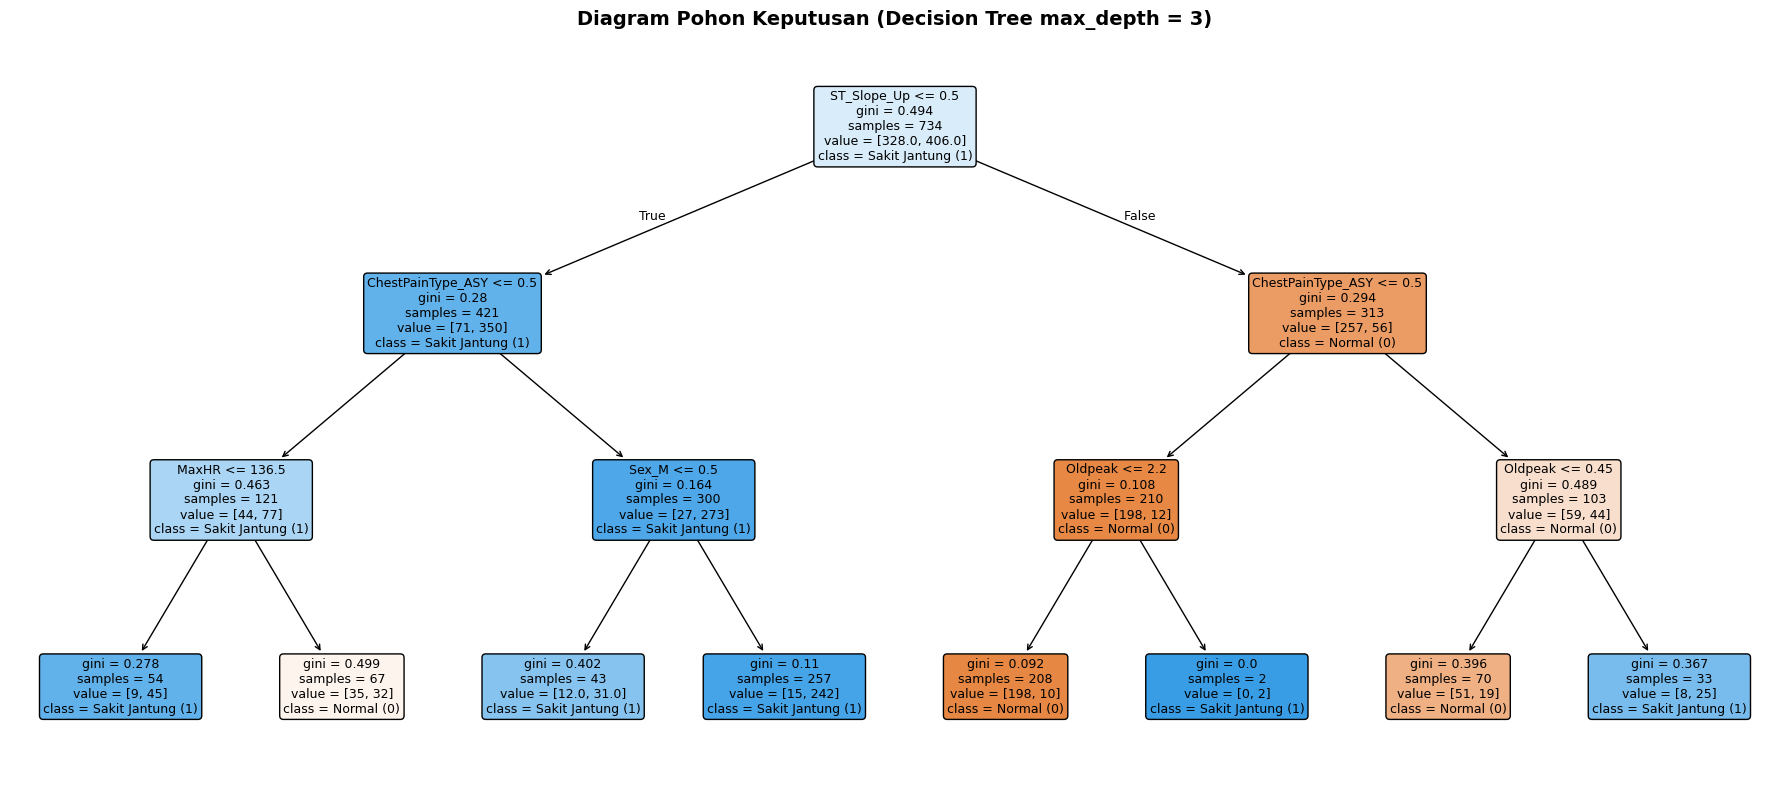

Aturan Keputusan dalam Bentuk Teks (IF-ELSE):
|--- ST_Slope_Up <= 0.50
|   |--- ChestPainType_ASY <= 0.50
|   |   |--- MaxHR <= 136.50
|   |   |   |--- class: 1
|   |   |--- MaxHR >  136.50
|   |   |   |--- class: 0
|   |--- ChestPainType_ASY >  0.50
|   |   |--- Sex_M <= 0.50
|   |   |   |--- class: 1
|   |   |--- Sex_M >  0.50
|   |   |   |--- class: 1
|--- ST_Slope_Up >  0.50
|   |--- ChestPainType_ASY <= 0.50
|   |   |--- Oldpeak <= 2.20
|   |   |   |--- class: 0
|   |   |--- Oldpeak >  2.20
|   |   |   |--- class: 1
|   |--- ChestPainType_ASY >  0.50
|   |   |--- Oldpeak <= 0.45
|   |   |   |--- class: 0
|   |   |--- Oldpeak >  0.45
|   |   |   |--- class: 1

